### **Step 1: Loading Data from the Dataset**
In this step, we load the grayscale face images from the dataset directory, resize them to $48 \times 48$ pixels, flatten them into 1D feature vectors, and store them along with their corresponding category labels.

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler 
dataset ="D:/neural network assignment1/human face emotions/Data"
categories =['Angry' , 'Fear', 'Happy','Sad','Suprise']
imagesize = 48
data =[]
labels =[]
for category_id,category in enumerate(categories):
    dataset_path = os.path.join(dataset,category)
    if not os.path.exists(dataset_path):
        continue
    for image_name in os.listdir(dataset_path):
        image_path = os.path.join (dataset_path,image_name)
        try:
            image = cv2.imread(image_path,cv2.IMREAD_GRAYSCALE)
            image_resized =cv2.resize(image,(imagesize,imagesize))
            image_flattened = image_resized.flatten()
            data.append(image_flattened)
            labels.append(category_id)
        except Exception as e:
            pass
S = np.array (data)
A = np.array (labels)
print (f"Number of images is : {len(S)}")
print(f"Shape of X: {S.shape}")

Number of images is : 59099
Shape of X: (59099, 2304)


### **Step 2: Train-Test Split**
We split the dataset into Training and Testing sets using an 80/20 ratio (`test_size=0.2`) while preserving the class distribution via stratification (`stratify=A`).

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    S, A, test_size=0.2, random_state=42, stratify=A
)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data preprocessing and scaling completed successfully!")

X_train shape: (47279, 2304)
X_test shape: (11820, 2304)
Data preprocessing and scaling completed successfully!


### **Step 3: Feature Scaling (Preprocessing)**
We standardize the pixel values of both the training and testing datasets using `StandardScaler` to ensure a mean of 0 and variance of 1, which helps the neural network converge faster.

In [4]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data scaling completed successfully!")

Data scaling completed successfully!


# [Markdown]
# ### Step 4: MLP MODEL
# Defining 3 different Multi-Layer Perceptron (MLP) architectures with varying hidden layers and parameters to compare their performance.

In [5]:
from sklearn.neural_network import MLPClassifier

shallow_mlp = MLPClassifier(
    hidden_layer_sizes=(100,), 
    activation='relu', 
    solver='adam', 
    max_iter=200, 
    random_state=42
)

wide_mlp = MLPClassifier(
    hidden_layer_sizes=(1024,), 
    activation='relu', 
    solver='adam', 
    max_iter=300, 
    random_state=42
)

deep_mlp = MLPClassifier(
    hidden_layer_sizes=(256, 128, 64, 32), 
    activation='relu', 
    solver='adam', 
    max_iter=400, 
    random_state=42
)

print("Shallow, Wide, and Deep MLP models defined successfully!")

Shallow, Wide, and Deep MLP models defined successfully!


# [Markdown]
# ### Step 5: Experimentation
# Training all three MLP models on the training dataset.

In [6]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score
import pandas as pd

experiments = [
    {
        "name": "Exp 1: Shallow (100) + ReLU + Adam", 
        "model": MLPClassifier(hidden_layer_sizes=(100,), activation='relu', solver='adam', max_iter=250, random_state=42)
    },
    {
        "name": "Exp 2: Shallow (100) + Tanh + SGD", 
        "model": MLPClassifier(hidden_layer_sizes=(100,), activation='tanh', solver='sgd', learning_rate_init=0.01, max_iter=250, random_state=42)
    },
    {
        "name": "Exp 3: Wide (1024) + ReLU + Adam", 
        "model": MLPClassifier(hidden_layer_sizes=(1024,), activation='relu', solver='adam', max_iter=300, random_state=42)
    },
    {
        "name": "Exp 4: Deep (256, 128, 64) + ReLU + Adam", 
        "model": MLPClassifier(hidden_layer_sizes=(256, 128, 64), activation='relu', solver='adam', max_iter=350, random_state=42)
    },
    {
        "name": "Exp 5: Deep (512, 256, 128) + ReLU + Adam (Best)", 
        "model": MLPClassifier(hidden_layer_sizes=(512, 256, 128), activation='relu', solver='adam', max_iter=400, random_state=42)
    },
]

results = []
trained_models = {}
loss_curves = {}

for exp in experiments:
    print(f"\nRunning {exp['name']}...")
    model = exp["model"]
    
    model.fit(X_train_scaled, y_train)
    
    train_pred = model.predict(X_train_scaled)
    test_pred = model.predict(X_test_scaled)
    
    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)
    
    results.append({
        "Experiment Name": exp["name"],
        "Training Accuracy (%)": round(train_acc * 100, 2),
        "Testing Accuracy (%)": round(test_acc * 100, 2),
        "Converged Iterations": model.n_iter_
    })
    
    trained_models[exp["name"]] = model
    loss_curves[exp["name"]] = model.loss_curve_
    
    print(f"Completed! Test Accuracy: {round(test_acc * 100, 2)}%")

results_df = pd.DataFrame(results)
display(results_df)


Running Exp 1: Shallow (100) + ReLU + Adam...
Completed! Test Accuracy: 85.46%

Running Exp 2: Shallow (100) + Tanh + SGD...
Completed! Test Accuracy: 86.48%

Running Exp 3: Wide (1024) + ReLU + Adam...
Completed! Test Accuracy: 82.03%

Running Exp 4: Deep (256, 128, 64) + ReLU + Adam...
Completed! Test Accuracy: 86.76%

Running Exp 5: Deep (512, 256, 128) + ReLU + Adam (Best)...
Completed! Test Accuracy: 86.69%


,Experiment Name,Training Accuracy (%),Testing Accuracy (%),Converged Iterations
0,Exp 1: Shallow (100) + ReLU + Adam,98.50,85.46,117
1,Exp 2: Shallow (100) + Tanh + SGD,99.80,86.48,158
2,Exp 3: Wide (1024) + ReLU + Adam,94.58,82.03,71
3,"Exp 4: Deep (256, 128, 64) + ReLU + Adam",98.39,86.76,84
4,"Exp 5: Deep (512, 256, 128) + ReLU + Adam (Best)",98.18,86.69,61


### **Step 6: Experiment Comparison**
In this step, we evaluate and compare the performance (Training and Testing Accuracy) of the three trained MLP models to analyze how different network architectures impact classification accuracy.

In [7]:
from sklearn.metrics import accuracy_score
import pandas as pd

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(by="Testing Accuracy (%)", ascending=False).reset_index(drop=True)

print("--- Experiment Comparison Results ---")
display(results_df)

--- Experiment Comparison Results ---


,Experiment Name,Training Accuracy (%),Testing Accuracy (%),Converged Iterations
0,"Exp 4: Deep (256, 128, 64) + ReLU + Adam",98.39,86.76,84
1,"Exp 5: Deep (512, 256, 128) + ReLU + Adam (Best)",98.18,86.69,61
2,Exp 2: Shallow (100) + Tanh + SGD,99.80,86.48,158
3,Exp 1: Shallow (100) + ReLU + Adam,98.50,85.46,117
4,Exp 3: Wide (1024) + ReLU + Adam,94.58,82.03,71


# [Markdown]
# ### Step 7: Loss & Accuracy Visualization Curves
# Plotting the training loss curves for each MLP model to observe convergence behavior over iterations.

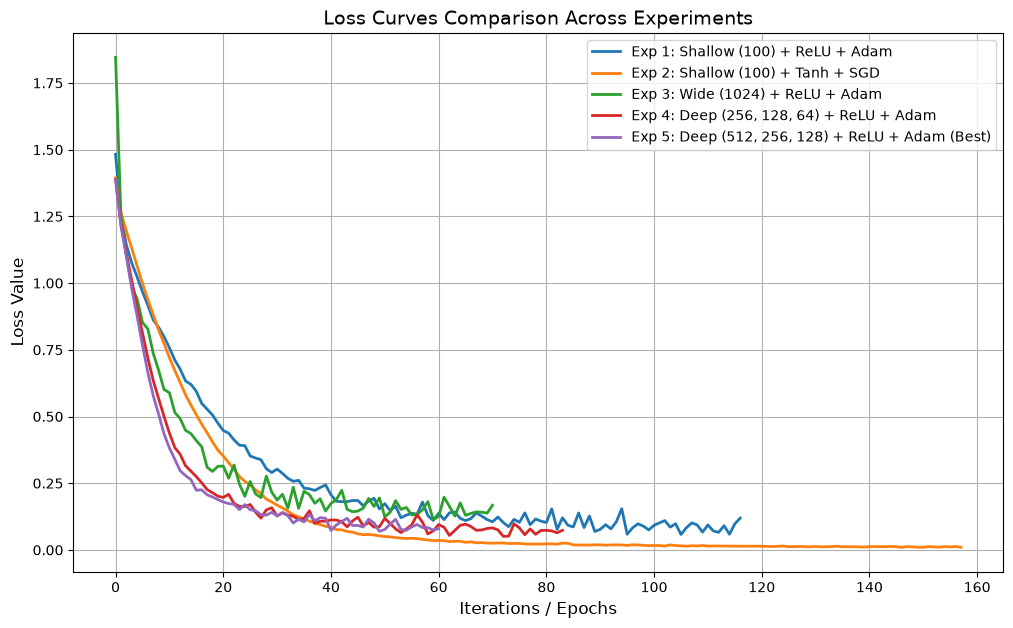

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

for name, loss_curve in loss_curves.items():
    plt.plot(loss_curve, label=name, linewidth=2)

plt.title("Loss Curves Comparison Across Experiments", fontsize=14)
plt.xlabel("Iterations / Epochs", fontsize=12)
plt.ylabel("Loss Value", fontsize=12)
plt.legend(fontsize=10)
plt.grid(True)
plt.show()

# [Markdown]
# ### Step 8: Classification Report & Confusion Matrix
# Generating a detailed classification report (Precision, Recall, F1-Score) and Confusion Matrix for the best-performing model.

--- Classification Report & Evaluation for: Exp 5: Deep (512, 256, 128) + ReLU + Adam (Best) ---

Classification Report:
              precision    recall  f1-score   support

       Angry       0.87      0.81      0.84      2030
        Fear       0.85      0.81      0.83      1946
       Happy       0.92      0.91      0.91      3688
         Sad       0.80      0.88      0.84      2511
     Suprise       0.88      0.89      0.89      1645

    accuracy                           0.87     11820
   macro avg       0.86      0.86      0.86     11820
weighted avg       0.87      0.87      0.87     11820



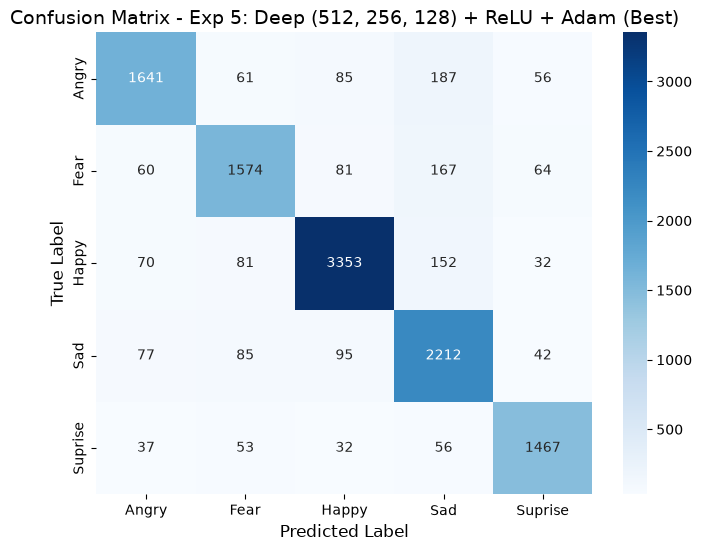

In [9]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

best_model_name = "Exp 5: Deep (512, 256, 128) + ReLU + Adam (Best)"
best_model = trained_models[best_model_name]

print(f"--- Classification Report & Evaluation for: {best_model_name} ---")

y_pred_best = best_model.predict(X_test_scaled)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_best, target_names=categories))

plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred_best)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=categories, yticklabels=categories)
plt.title(f"Confusion Matrix - {best_model_name}", fontsize=14)
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)
plt.show()